# <p style='color:orange'> dreampy tutorial</p>

This notebook walks through a complete pseudobulk differential expression
analysis using dreampy — from raw cell-level counts to results tables and
volcano plots. 

The dataset is a synthetic case/control study with four cell types and a
collection-site random effect. It ships with the repository so you can run
this notebook out of the box, then swap in your own `.h5ad` to apply the
same workflow to real data.

**Pipeline:**

`load → aggregate_pseudobulk → filter_samples → compute_tmm_factors →
filter_by_expr → log2cpm → estimate_weights → fit_models → ebayes →
get_results`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import dreampy as dp

from pathlib import Path

# Suppress specific warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)

### 1. Load the data
The tutorial dataset is a cell-level AnnData: ~8,000 cells × 500 genes,
with `obs` columns for `sample_id`, `celltype`, `condition`, and `site`.
It was generated by `generate_tutorial_data.py` in this directory.

In [2]:
DATA_DIR = Path("../data/tutorial")
adata = sc.read_h5ad(DATA_DIR / "tutorial_dataset.h5ad")
print(adata)
print(f"\nobs columns: {list(adata.obs.columns)}")
print(f"Cell types:  {adata.obs['celltype'].unique().tolist()}")
print(f"Conditions:  {adata.obs['condition'].unique().tolist()}")
print(f"Sites:       {adata.obs['site'].unique().tolist()}")
print(f"Donors:      {adata.obs['sample_id'].nunique()}")

AnnData object with n_obs × n_vars = 8050 × 500
    obs: 'sample_id', 'celltype', 'condition', 'site'

obs columns: ['sample_id', 'celltype', 'condition', 'site']
Cell types:  ['celltype_A', 'celltype_B', 'celltype_C', 'celltype_D']
Conditions:  ['case', 'control']
Sites:       ['site_A', 'site_B', 'site_C', 'site_D']
Donors:      40


A quick look at the experimental design: how many cells per donor and
cell type, and how the donors are distributed across conditions and sites.

In [3]:
design = (
    adata.obs
    .groupby(["celltype", "condition", "site"], observed=False)["sample_id"]
    .nunique()
    .unstack("site")
)
print("Donors per celltype × condition × site:")
print(design)

Donors per celltype × condition × site:
site                  site_A  site_B  site_C  site_D
celltype   condition                                
celltype_A case            5       5       5       5
           control         5       5       5       5
celltype_B case            5       5       5       5
           control         5       5       5       5
celltype_C case            5       5       5       5
           control         5       5       5       5
celltype_D case            5       5       5       5
           control         5       5       5       5


### 2. Pseudobulk aggregation

`aggregate_pseudobulk` sums cell-level counts within each combination of
the `groupby` variables, producing a samples-by-genes AnnData where each
"sample" is one pseudobulk profile. The `groupby` list should include:

 - the cell-type column (creates one assay per cell type)
 - the biological replicate (donor/subject)
 - any additional grouping variables in your formula's random effects

 The resulting object carries an `assays` column in `.obs` that tags each
 pseudobulk sample with its cell type.

In [4]:
GROUPBY = ["celltype", "sample_id", "site"]
FORMULA = "~ condition + (1|site)"

pb = dp.aggregate_pseudobulk(adata, groupby=GROUPBY)
print(pb)
print(f"\nAssays: {pb.obs['assays'].unique().tolist()}")
print(f"Samples per assay:")
print(pb.obs["assays"].value_counts())

AnnData object with n_obs × n_vars = 160 × 500
    obs: 'assays', 'celltype', 'sample_id', 'site', 'condition', 'n_cells', 'total_counts'

Assays: ['celltype_A', 'celltype_B', 'celltype_C', 'celltype_D']
Samples per assay:
assays
celltype_A    40
celltype_B    40
celltype_C    40
celltype_D    40
Name: count, dtype: int64


/Users/sw2233/miniforge3/envs/dreampy/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


### 3. Sample filtering

`filter_samples` removes pseudobulk samples backed by too few cells and
drops any assay (cell type) that doesn't have enough samples remaining.
This protects against noisy pseudobulk profiles from rare cell types.

In [5]:
pb = dp.filter_samples(pb, min_cells=5, min_samples=3)
print(f"After filter_samples: {pb.shape[0]} samples, {pb.shape[1]} genes")
print(pb.obs["assays"].value_counts())

  celltype_A: 40 samples retained
  celltype_B: 40 samples retained
  celltype_C: 40 samples retained
  celltype_D: 40 samples retained
filter_samples: 160/160 samples, 4 assays retained, 0 dropped
After filter_samples: 160 samples, 500 genes
assays
celltype_A    40
celltype_B    40
celltype_C    40
celltype_D    40
Name: count, dtype: int64


### 4. TMM normalization

Trimmed Mean of M-values (TMM) normalization computes per-sample scaling
factors that account for compositional differences in library size. This
operates on the full gene set, before gene filtering — the same gene
universe is used to estimate normalization factors across all assays.

In [6]:
pb = dp.compute_tmm_factors(pb, assay_col="assays")

# Sanity check: geometric mean of norm_factors should be ~1.0
nf = pb.obs["norm_factors"].values
geo_mean = np.exp(np.mean(np.log(nf)))
print(f"TMM norm_factors: min={nf.min():.4f}, max={nf.max():.4f}, "
      f"geometric mean={geo_mean:.6f}")

compute_tmm_factors: TMM normalization complete (4 assays, 160 samples)
TMM norm_factors: min=0.9196, max=1.0814, geometric mean=1.000000


### 5. Gene filtering

 `filter_by_expr` applies per-assay gene filtering using edgeR's
 `filterByExpr` logic: genes must have sufficient counts in a sufficient
 proportion of samples within each cell type. This returns a **dict** of
 per-assay AnnData objects, each containing only the genes that passed
 filtering for that cell type.

 This is the step where the multi-assay structure materializes: from here
 on, each cell type is processed independently.

In [7]:
assays_dict = dp.filter_by_expr(pb, assay_col="assays")

print(f"{'Cell type':<15} {'Samples':>8} {'Genes (pre)':>12} {'Genes (post)':>13}")
print("-" * 50)
for name, assay_pb in assays_dict.items():
    print(f"{name:<15} {assay_pb.shape[0]:>8} {pb.shape[1]:>12} {assay_pb.shape[1]:>13}")

filter_by_expr: filtering 4 assays
  celltype_A: 452/500 genes retained (48 filtered out)
  celltype_B: 463/500 genes retained (37 filtered out)
  celltype_C: 454/500 genes retained (46 filtered out)
  celltype_D: 456/500 genes retained (44 filtered out)
Cell type        Samples  Genes (pre)  Genes (post)
--------------------------------------------------
celltype_A            40          500           452
celltype_B            40          500           463
celltype_C            40          500           454
celltype_D            40          500           456


### 6. Per-assay pipeline: log2CPM → voom → fit → eBayes

 Now we loop over cell types and run the remaining steps on each
 filtered assay independently:

 1. **log2cpm** — log2 counts per million with a prior count of 0.5
 2. **estimate_weights** — voom precision weights from the mean-variance
    trend, using the formula's fixed + random effects
 3. **fit_models** — weighted mixed-model fits with Satterthwaite
    denominator degrees of freedom
 4. **ebayes** — empirical Bayes moderation of the residual variance
 5. **get_results** — extract a tidy results table with logFC, t, p, and
    adjusted p-values


── celltype_A ──
log2cpm: transformation complete (40 samples, 452 genes)
Formula cleaned: 1 fixed effect(s), 1 random effect(s)
estimate_weights: Fitting 452 genes with formula '~ condition + (1|site)'...


Fitting genes: 100%|██████████| 452/452 [00:01<00:00, 308.81it/s]


estimate_weights: 452/452 genes converged with valid sigma
estimate_weights: Weights stored in .layers['weights']
estimate_weights: Voom info stored in .uns['voom_info']


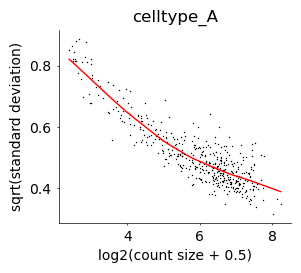

Formula cleaned: 1 fixed effect(s), 1 random effect(s)


Fitting genes: 100%|██████████| 452/452 [00:00<00:00, 3158.92it/s]


  fit: DEFit: 452 genes × 40 samples
  Formula: ~ condition + (1|site)
  Method: lmm (REML)
  Coefficients: ['(Intercept)', 'condition_control']
  Test space: coef
  Fit status: 448 success, 0 failed, 4 boundary
  eBayes applied: False
  DDF method: Satterthwaite
  eBayes: s2_prior=0.0486, df_prior=5.2
  Results: 452 genes, 142 significant (FDR < 0.05)

── celltype_B ──
log2cpm: transformation complete (40 samples, 463 genes)
Formula cleaned: 1 fixed effect(s), 1 random effect(s)
estimate_weights: Fitting 463 genes with formula '~ condition + (1|site)'...


Fitting genes: 100%|██████████| 463/463 [00:00<00:00, 3785.43it/s]


estimate_weights: 463/463 genes converged with valid sigma
estimate_weights: Weights stored in .layers['weights']
estimate_weights: Voom info stored in .uns['voom_info']


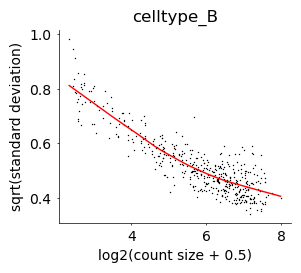

Formula cleaned: 1 fixed effect(s), 1 random effect(s)


Fitting genes: 100%|██████████| 463/463 [00:00<00:00, 3282.78it/s]


  fit: DEFit: 463 genes × 40 samples
  Formula: ~ condition + (1|site)
  Method: lmm (REML)
  Coefficients: ['(Intercept)', 'condition_control']
  Test space: coef
  Fit status: 458 success, 0 failed, 5 boundary
  eBayes applied: False
  DDF method: Satterthwaite
  eBayes: s2_prior=0.0521, df_prior=4.7
  Results: 463 genes, 66 significant (FDR < 0.05)

── celltype_C ──
log2cpm: transformation complete (40 samples, 454 genes)
Formula cleaned: 1 fixed effect(s), 1 random effect(s)
estimate_weights: Fitting 454 genes with formula '~ condition + (1|site)'...


Fitting genes: 100%|██████████| 454/454 [00:00<00:00, 3205.53it/s]


estimate_weights: 454/454 genes converged with valid sigma
estimate_weights: Weights stored in .layers['weights']
estimate_weights: Voom info stored in .uns['voom_info']


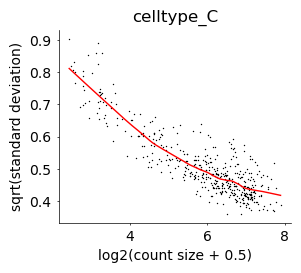

Formula cleaned: 1 fixed effect(s), 1 random effect(s)


Fitting genes: 100%|██████████| 454/454 [00:00<00:00, 3177.49it/s]


  fit: DEFit: 454 genes × 40 samples
  Formula: ~ condition + (1|site)
  Method: lmm (REML)
  Coefficients: ['(Intercept)', 'condition_control']
  Test space: coef
  Fit status: 448 success, 0 failed, 6 boundary
  eBayes applied: False
  DDF method: Satterthwaite
  eBayes: s2_prior=0.0508, df_prior=5.6
  Results: 454 genes, 0 significant (FDR < 0.05)

── celltype_D ──
log2cpm: transformation complete (40 samples, 456 genes)
Formula cleaned: 1 fixed effect(s), 1 random effect(s)
estimate_weights: Fitting 456 genes with formula '~ condition + (1|site)'...


Fitting genes: 100%|██████████| 456/456 [00:00<00:00, 3284.42it/s]


estimate_weights: 456/456 genes converged with valid sigma
estimate_weights: Weights stored in .layers['weights']
estimate_weights: Voom info stored in .uns['voom_info']


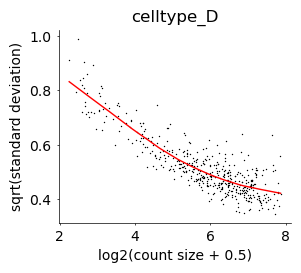

Formula cleaned: 1 fixed effect(s), 1 random effect(s)


Fitting genes: 100%|██████████| 456/456 [00:00<00:00, 3614.23it/s]


  fit: DEFit: 456 genes × 40 samples
  Formula: ~ condition + (1|site)
  Method: lmm (REML)
  Coefficients: ['(Intercept)', 'condition_control']
  Test space: coef
  Fit status: 453 success, 0 failed, 3 boundary
  eBayes applied: False
  DDF method: Satterthwaite
  eBayes: s2_prior=0.0518, df_prior=5.2
  Results: 456 genes, 139 significant (FDR < 0.05)


In [ ]:
def voom_plot(assay_pb, assay_name, figsize=(3, 2.5)):
    """Voom mean-variance trend plot from a processed AnnData."""
    vi = assay_pb.uns["voom_info"]
    sx, sy = vi["trend_xy"]["x"], vi["trend_xy"]["y"]
    lx, ly = vi["trend_line"]["x"], vi["trend_line"]["y"]

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(sx, sy, s=1, c="k", linewidths=0)
    ax.plot(lx, ly, c="red", linewidth=1)

    ax.set_xlabel("log2(count size + 0.5)")
    ax.set_ylabel("sqrt(standard deviation)")
    ax.set_title(assay_name)

    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    for spine in ("left", "bottom"):
        ax.spines[spine].set_linewidth(0.5)
    ax.tick_params(length=1.5, width=0.5)

    return fig

all_results = {}

for assay_name, assay_pb in assays_dict.items():
    print(f"\n── {assay_name} ──")

    # log2CPM
    assay_pb = dp.log2cpm(assay_pb)

    # Voom weights
    assay_pb = dp.estimate_weights(
        assay_pb, formula=FORMULA, n_jobs=-1,
    )

    voom_plot(assay_pb, assay_name)
    plt.show()

    # Mixed-model fitting
    fit = dp.fit_models(
        assay_pb,
        formula=FORMULA,
        reml=True,
        n_jobs=-1,
        assay_name=assay_name,
    )
    print(f"  fit: {fit}")

    # eBayes
    fit_eb = dp.ebayes(fit)
    print(f"  eBayes: s2_prior={fit_eb.s2_prior:.4f}, "
          f"df_prior={fit_eb.df_prior:.1f}")

    # Results table
    results = dp.get_results(fit_eb, assay_name=assay_name)
    all_results[assay_name] = results
    print(f"  Results: {len(results)} genes, "
          f"{(results['adj_p_val'] < 0.05).sum()} significant (FDR < 0.05)")


### 7. Inspect results
 `get_results` returns a DataFrame with one row per gene, including
 log-fold-change, moderated t-statistic, raw p-value, and BH-adjusted
 p-value. Let's look at the top hits from celltype_A.

In [9]:
res_a = all_results["celltype_A"].sort_values("p_value")
print(res_a.head(20).to_string())

         assay               coef         id     logfc   ave_expr          t       p_value     adj_p_val          b     z_std
0   celltype_A  condition_control  gene_0065 -1.220379  12.700027 -30.946151  1.183381e-29  5.348882e-27  57.613350 -8.026859
1   celltype_A  condition_control  gene_0046 -1.792960  12.365346 -30.159370  3.192949e-29  7.216065e-27  56.622846 -8.026859
2   celltype_A  condition_control  gene_0461 -1.427349  12.802697 -29.605251  6.526365e-29  9.833056e-27  55.906450 -8.026859
3   celltype_A  condition_control  gene_0275 -1.374299  12.095198 -28.759096  1.998267e-28  2.258041e-26  54.789624 -8.026859
4   celltype_A  condition_control  gene_0354 -1.893561  12.073844 -27.928303  6.140699e-28  5.551192e-26  53.670911 -8.026859
5   celltype_A  condition_control  gene_0045 -1.198888  12.900984 -27.388938  1.287127e-27  9.696359e-26  52.906592 -8.026859
6   celltype_A  condition_control  gene_0209 -1.282408  12.069957 -27.137437  1.831038e-27  1.182327e-25  52.561587 -8

### Summary across cell types

 A quick comparison of how many genes are significant in each cell type
 shows the cell-type-specific nature of the DE signal.

In [10]:
summary_rows = []
for ct, res in all_results.items():
    n_sig_005 = (res["adj_p_val"] < 0.05).sum()
    n_sig_lfc = ((res["adj_p_val"] < 0.05) & (res["logfc"].abs() > 0.5)).sum()
    summary_rows.append({
        "celltype": ct,
        "genes_tested": len(res),
        "FDR < 0.05": n_sig_005,
        "FDR < 0.05 & |logFC| > 0.5": n_sig_lfc,
    })
summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False))

  celltype  genes_tested  FDR < 0.05  FDR < 0.05 & |logFC| > 0.5
celltype_A           452         142                         125
celltype_B           463          66                          53
celltype_C           454           0                           0
celltype_D           456         139                         125


### 8. Volcano plot

 A volcano plot shows the relationship between effect size (logFC) and
 statistical significance (-log10 p-value). We'll plot celltype_A as an
 example.

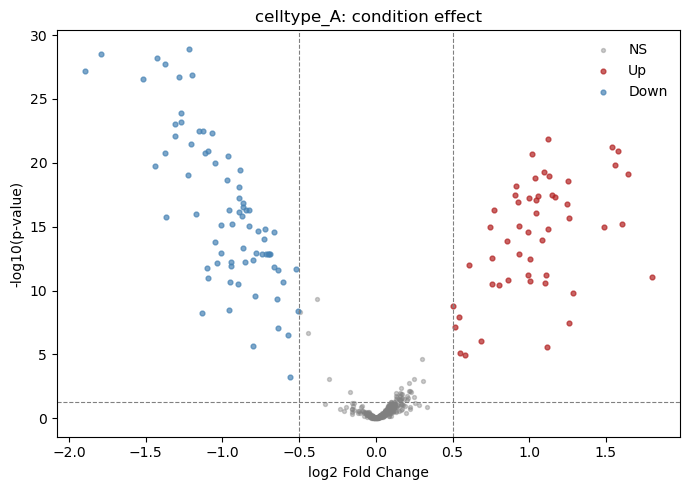

In [11]:
def volcano_plot(results, title, fdr_threshold=0.05, lfc_threshold=0.5):
    """Simple volcano plot from a dreampy results table."""
    res = results.copy()
    res["-log10p"] = -np.log10(res["p_value"].clip(lower=1e-300))

    sig = (res["adj_p_val"] < fdr_threshold) & (res["logfc"].abs() > lfc_threshold)
    sig_up = sig & (res["logfc"] > 0)
    sig_down = sig & (res["logfc"] < 0)
    ns = ~sig

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(res.loc[ns, "logfc"], res.loc[ns, "-log10p"],
               c="grey", alpha=0.4, s=8, label="NS")
    ax.scatter(res.loc[sig_up, "logfc"], res.loc[sig_up, "-log10p"],
               c="firebrick", alpha=0.7, s=12, label="Up")
    ax.scatter(res.loc[sig_down, "logfc"], res.loc[sig_down, "-log10p"],
               c="steelblue", alpha=0.7, s=12, label="Down")

    ax.axhline(-np.log10(fdr_threshold), ls="--", lw=0.8, c="grey")
    ax.axvline(-lfc_threshold, ls="--", lw=0.8, c="grey")
    ax.axvline(lfc_threshold, ls="--", lw=0.8, c="grey")

    ax.set_xlabel("log2 Fold Change")
    ax.set_ylabel("-log10(p-value)")
    ax.set_title(title)
    ax.legend(frameon=False)
    plt.tight_layout()
    return fig

fig = volcano_plot(all_results["celltype_A"], "celltype_A: condition effect")
plt.show()

### Volcano plots for all cell types

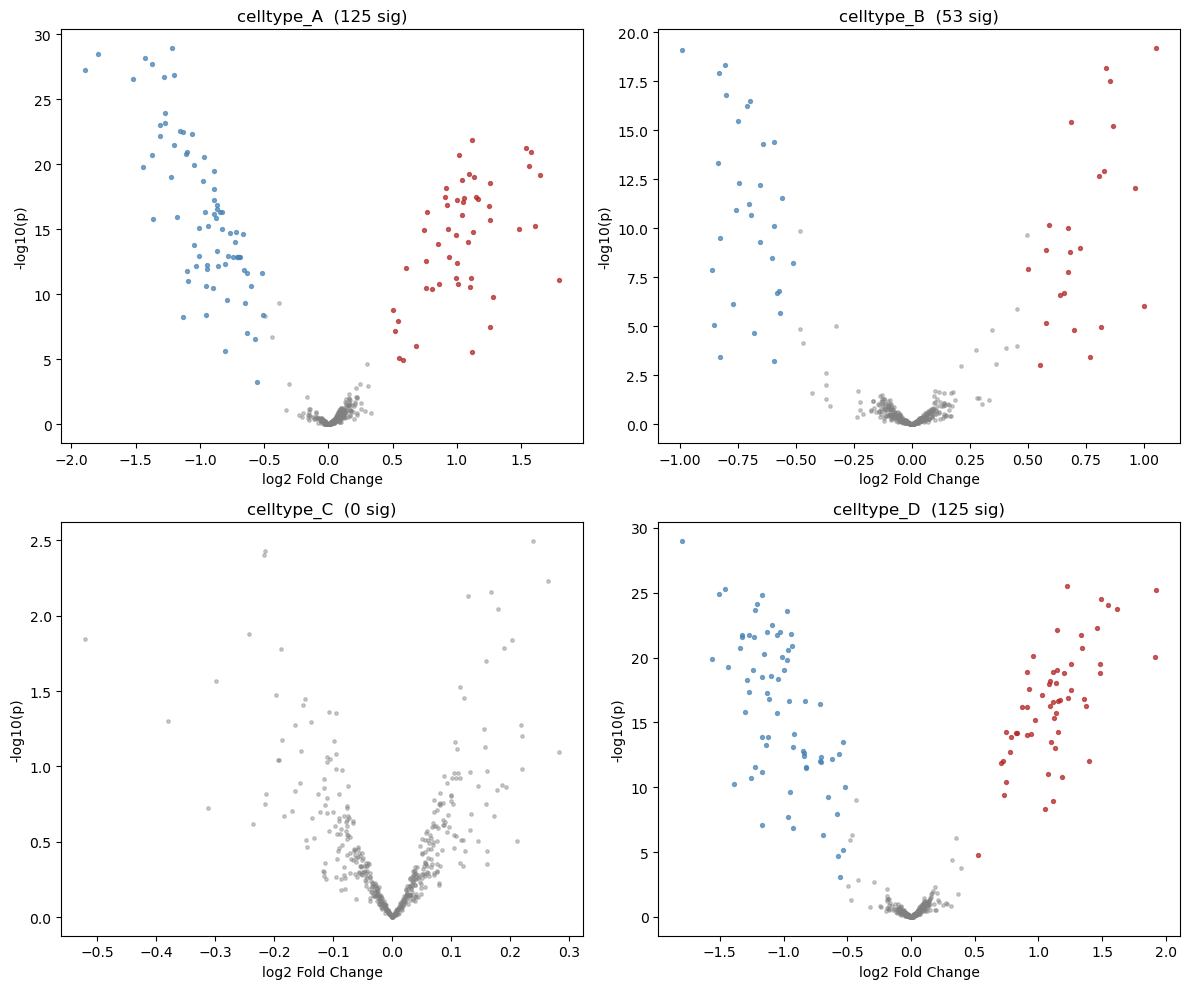

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (ct, res) in zip(axes.flat, all_results.items()):
    res = res.copy()
    res["-log10p"] = -np.log10(res["p_value"].clip(lower=1e-300))

    sig = (res["adj_p_val"] < 0.05) & (res["logfc"].abs() > 0.5)
    sig_up = sig & (res["logfc"] > 0)
    sig_down = sig & (res["logfc"] < 0)
    ns = ~sig

    ax.scatter(res.loc[ns, "logfc"], res.loc[ns, "-log10p"],
               c="grey", alpha=0.4, s=6)
    ax.scatter(res.loc[sig_up, "logfc"], res.loc[sig_up, "-log10p"],
               c="firebrick", alpha=0.7, s=8)
    ax.scatter(res.loc[sig_down, "logfc"], res.loc[sig_down, "-log10p"],
               c="steelblue", alpha=0.7, s=8)

    n_sig = sig.sum()
    ax.set_title(f"{ct}  ({n_sig} sig)")
    ax.set_xlabel("log2 Fold Change")
    ax.set_ylabel("-log10(p)")

plt.tight_layout()
plt.show()

### 9. Comparing across cell types

 Because celltype_D was designed to share ~half its DE genes with
 celltype_A, we can check that overlap. This mirrors what you'd do in a
 real analysis to identify shared vs. cell-type-specific responses.

In [13]:
sig_genes = {}
for ct, res in all_results.items():
    sig_genes[ct] = set(
        res.loc[(res["adj_p_val"] < 0.05) & (res["logfc"].abs() > 0.5), "id"]
    )

a_genes = sig_genes.get("celltype_A", set())
d_genes = sig_genes.get("celltype_D", set())

if a_genes and d_genes:
    overlap = a_genes & d_genes
    a_only = a_genes - d_genes
    d_only = d_genes - a_genes

    print(f"celltype_A significant: {len(a_genes)}")
    print(f"celltype_D significant: {len(d_genes)}")
    print(f"Shared:                 {len(overlap)}")
    print(f"A only:                 {len(a_only)}")
    print(f"D only:                 {len(d_only)}")
else:
    print("Not enough significant genes to compare.")

celltype_A significant: 125
celltype_D significant: 125
Shared:                 50
A only:                 75
D only:                 75


### 10. Check against ground truth

 Since this is synthetic data, we can load the gene manifest to see how
 well the pipeline recovered the true DE genes. In a real analysis you
 wouldn't have this — but it's useful for building intuition about power
 and false discovery rates.

In [14]:
manifest = pd.read_csv(DATA_DIR / "gene_manifest.csv")

for ct in all_results:
    res = all_results[ct]
    de_col = f"de_{ct}"
    if de_col not in manifest.columns:
        continue

    truth = manifest.set_index("gene")[de_col]
    res_m = res.set_index("id").join(truth, how="left")

    called_sig = (res_m["adj_p_val"] < 0.05) & (res_m["logfc"].abs() > 0.5)
    truly_de = res_m[de_col] == True

    tp = (called_sig & truly_de).sum()
    fp = (called_sig & ~truly_de).sum()
    fn = (~called_sig & truly_de).sum()
    tn = (~called_sig & ~truly_de).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
    recall = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    fdr = fp / (tp + fp) if (tp + fp) > 0 else float("nan")

    print(f"{ct}: TP={tp}, FP={fp}, FN={fn}, TN={tn}  "
          f"(precision={precision:.2f}, recall={recall:.2f}, FDR={fdr:.2f})")

celltype_A: TP=125, FP=0, FN=6, TN=321  (precision=1.00, recall=0.95, FDR=0.00)
celltype_B: TP=53, FP=0, FN=18, TN=392  (precision=1.00, recall=0.75, FDR=0.00)
celltype_C: TP=0, FP=0, FN=0, TN=454  (precision=nan, recall=nan, FDR=nan)
celltype_D: TP=125, FP=0, FN=9, TN=322  (precision=1.00, recall=0.93, FDR=0.00)


### Next steps

 To use this workflow on your own data:

 1. Replace the `read_h5ad` call with your own cell-level AnnData.
 2. Set `GROUPBY` to `[celltype_col, sample_col, ...]` matching your
    experimental design.
 3. Set `FORMULA` to your fixed + random effects specification.
 4. Adjust `filter_samples` and `filter_by_expr` thresholds for your
    dataset's scale.

 The pipeline is the same regardless of the number of cell types, random
 effects, or covariates — dreampy handles the multi-assay iteration and
 mixed-model fitting automatically.